# Sentiment of product reviews with an LSTM - and the effect of review length
This notebook walks through the 7 required steps. The expensive training is done by `python main.py` (about 40 min on CPU); here we re-run the cheap steps live (data, cleaning, tokenisation, model definition) and **display the saved results** (`results/`, `figures/`) so every number matches the report.

In [1]:
import sys, json, os
os.chdir(r'E:\Projects\NLP Model - SR'); sys.path.insert(0, '.')
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 200, 'display.max_colwidth', 120)
from src.config import Config
from src import data, preprocess as pp
cfg = Config(); R, F = cfg.results, cfg.figures

## Step 1 - Load a labelled review dataset
Amazon Polarity (Hugging Face): 1-2 star = negative, 4-5 star = positive, no neutral reviews. We draw a class-balanced sample and make a stratified 70/15/15 split.

In [2]:
df = data.split_data(data.load_reviews(cfg), cfg)
data.summarize(df, cfg)

[data] loaded cached sample reviews_60000_seed42.csv
[data] 60,000 reviews used
       negative  positive
split                    
test       4500      4500
train     21000     21000
val        4500      4500

 label                                                                                                                                                             text
     0                                                              Fog Hat made only one good song they ever did, Slow Ride, therest of the CD is crap!!!!!! Good bug.
     0 The UV light went out on the sanitizer five days after using 24 hours a day. There is no restriction as to the amount of usage. Where can you get replacement li
     0 I thoroughly enjoy salsa, and enjoy learning from DVD's and tapes. The title and reviews of this product suggest one will learn great things about this lovely d
     1 I have used this book for reviewing cases in prepartion for neuroradiology and neurosurgery. It offers a wonde

## Step 2 - Clean and tokenize
Lower-casing, HTML/URL removal, contractions expanded (`didn't` -> `did not`), negations kept, `!`/`?` kept as tokens.

In [3]:
for t in df.text.iloc[:3]:
    print('RAW   :', t[:200]); print('TOKENS:', pp.tokenize(t)[:30]); print()
print(pp.tokenize("I don't like it, it isn't great and I can't recommend it!!!"))

RAW   : A complete waste of time. Typographical errors, poor grammar, and a totally pathetic plot add up to absolutely nothing. I'm embarrassed for this author and very disappointed I actually paid for this b
TOKENS: ['a', 'complete', 'waste', 'of', 'time', 'typographical', 'errors', 'poor', 'grammar', 'and', 'a', 'totally', 'pathetic', 'plot', 'add', 'up', 'to', 'absolutely', 'nothing', 'i', 'am', 'embarrassed', 'for', 'this', 'author', 'and', 'very', 'disappointed', 'i', 'actually']

RAW   : This book in my opinion is biased and takes an angle of Europe that is "clean and proper" and fails to shed light on the rest of it. I can understand that these are "tourist guides" and why would anyo
TOKENS: ['this', 'book', 'in', 'my', 'opinion', 'is', 'biased', 'and', 'takes', 'an', 'angle', 'of', 'europe', 'that', 'is', 'clean', 'and', 'proper', 'and', 'fails', 'to', 'shed', 'light', 'on', 'the', 'rest', 'of', 'it', 'i', 'can']

RAW   : Thia was a gift for my Husband, who loved the book. It a

{'vocab_size': 20000, 'max_len': 170, 'q33': 48.0, 'q67': 92.0, 'test_truncated_frac': 0.027666666666666666}


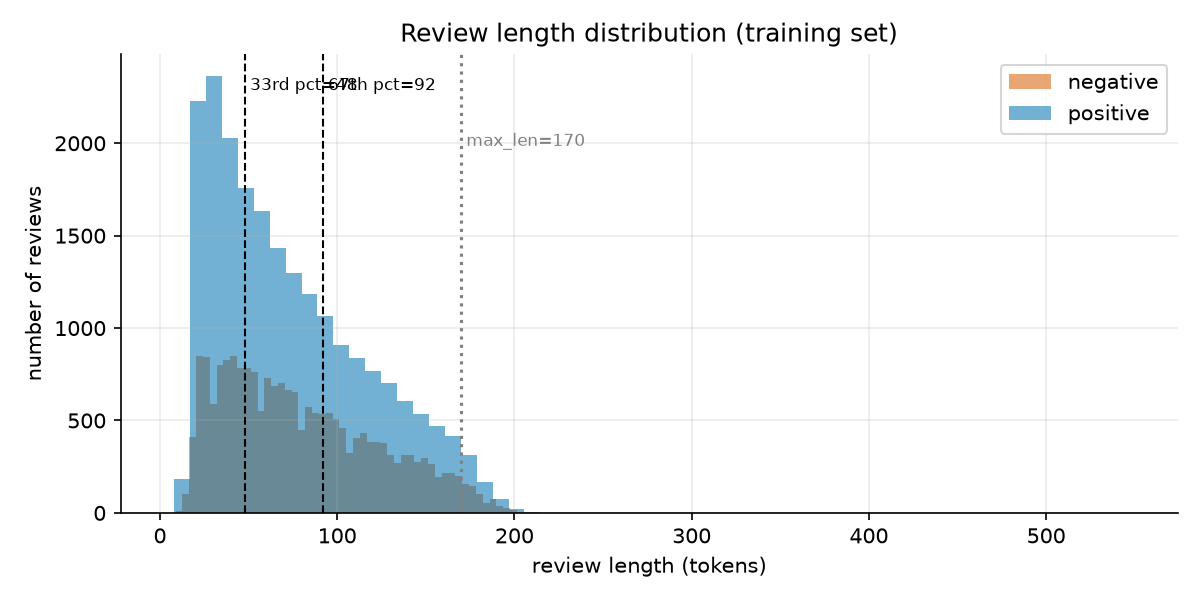

In [4]:
print(json.load(open(R/'preprocessing_info.json')))
display(Image(F/'length_distribution.png'))

## Step 3 - Embeddings
An `nn.Embedding` maps each token id to a trainable 100-d vector. We compare random-initialised vs GloVe-initialised.

In [5]:
import torch
from src.models import RecurrentClassifier, count_params
info = json.load(open(R/'preprocessing_info.json'))
m = RecurrentClassifier(info['vocab_size'], cfg.emb_dim, cfg.hidden, 'lstm', cfg.dropout)
print(m)
print('trainable parameters:', count_params(m))
x = torch.randint(2, 1000, (3, info['max_len'])); l = torch.tensor([10, 50, info['max_len']])
print('embedding output', m.embedding(x).shape, '| logits', m(x, l).shape)

RecurrentClassifier(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (rnn): LSTM(100, 128, batch_first=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
trainable parameters: 2117889


embedding output torch.Size([3, 170, 100]) | logits torch.Size([3])


## Step 4 - LSTM training (curves from the saved training run)

main LSTM (best validation accuracy): lstm_glove


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,0.4860,0.7711,0.3513,0.8574
1,2,0.2794,0.8890,0.2719,0.8918
2,3,0.1957,0.9262,0.3238,0.8841
3,4,0.1320,0.9527,0.3294,0.8827


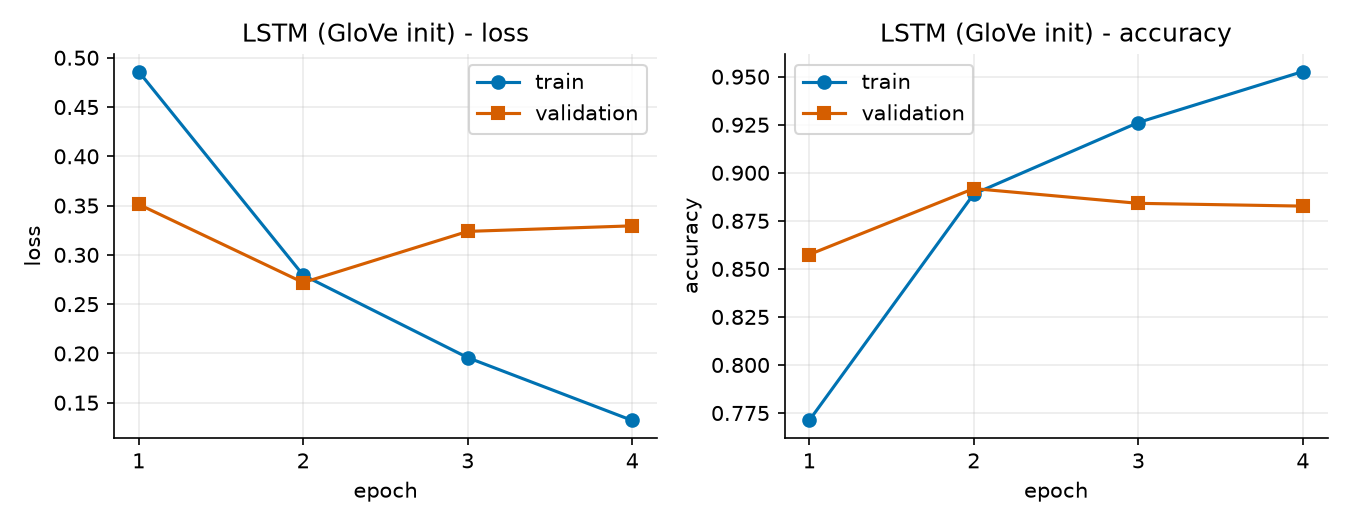

In [6]:
main = (R/'main_model.txt').read_text(); print('main LSTM (best validation accuracy):', main)
display(pd.read_csv(R/f'history_{main}.csv').round(4)); display(Image(F/f'training_curves_{main}.png'))

## Step 5 - Evaluation on the held-out test set

,model,accuracy,precision,recall,f1,train_seconds,parameters,epochs_run,best_epoch,best_val_acc
0,lstm_emb,0.8704,0.8790,0.8591,0.8690,963.2708,2117889,5.0,3.0,0.8762
1,lstm_glove,0.8854,0.9023,0.8644,0.8830,749.3345,2117889,4.0,2.0,0.8918
2,rnn,0.7999,0.8154,0.7753,0.7949,168.6473,2029569,6.0,4.0,0.8176
3,tfidf_lr,0.8918,0.8932,0.8900,0.8916,13.5486,200001,NaN,NaN,NaN


              precision    recall  f1-score   support

    negative     0.8699    0.9064    0.8878      4500
    positive     0.9023    0.8644    0.8830      4500

    accuracy                         0.8854      9000
   macro avg     0.8861    0.8854    0.8854      9000
weighted avg     0.8861    0.8854    0.8854      9000



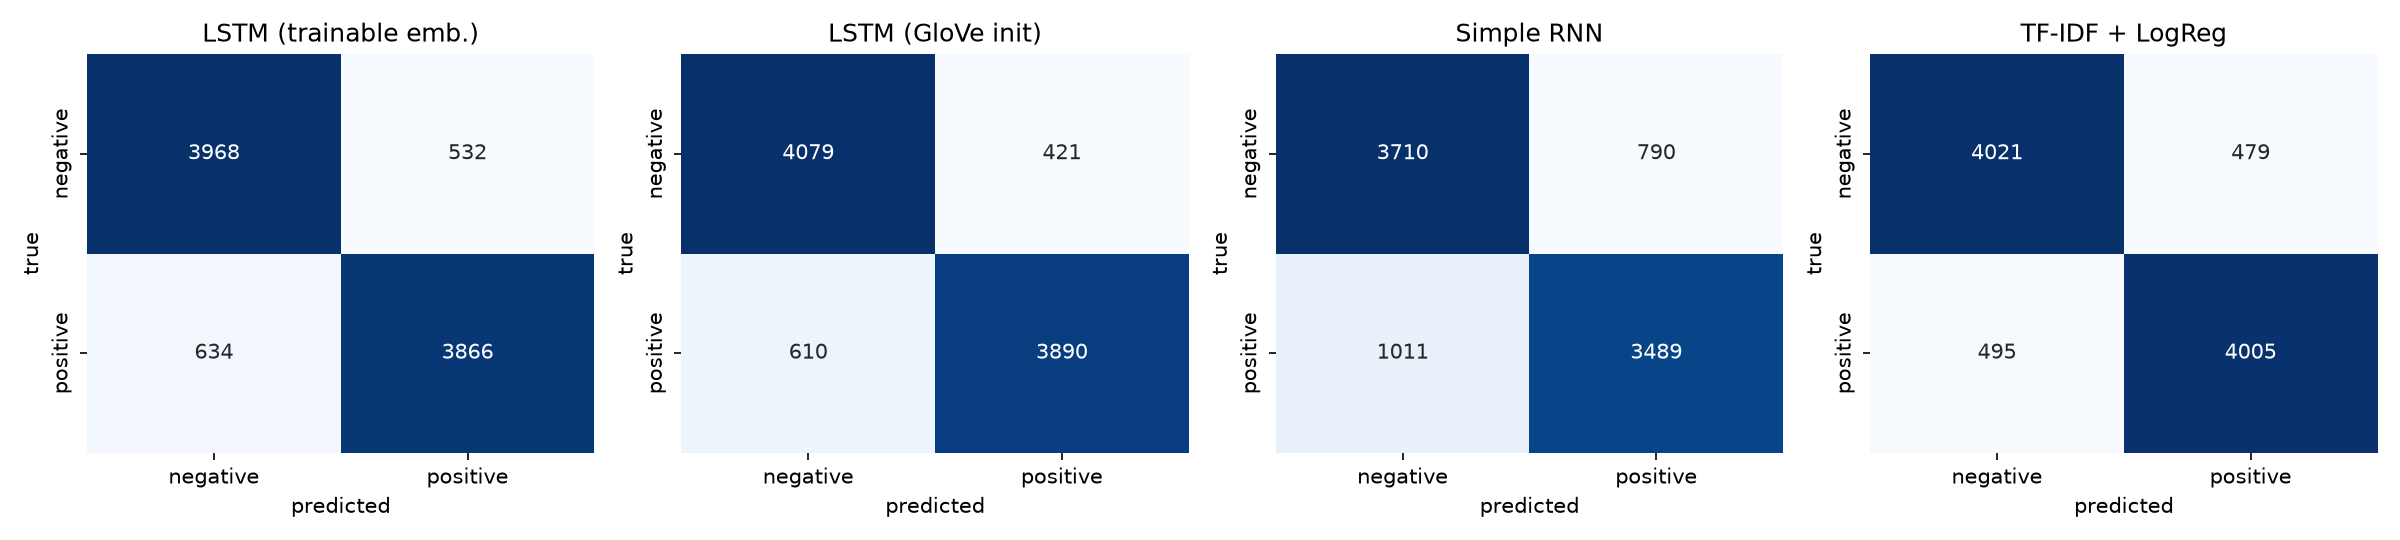

In [7]:
display(pd.read_csv(R/'metrics_overall.csv').round(4))
print((R/f'classification_report_{main}.txt').read_text())
display(Image(F/'confusion_matrices_all.png'))

## Step 6 - Comparison with baselines

,model,accuracy,precision,recall,f1,train_seconds,parameters,epochs_run,best_epoch,best_val_acc
0,lstm_emb,0.8704,0.8790,0.8591,0.8690,963.2708,2117889,5.0,3.0,0.8762
1,lstm_glove,0.8854,0.9023,0.8644,0.8830,749.3345,2117889,4.0,2.0,0.8918
2,rnn,0.7999,0.8154,0.7753,0.7949,168.6473,2029569,6.0,4.0,0.8176
3,tfidf_lr,0.8918,0.8932,0.8900,0.8916,13.5486,200001,NaN,NaN,NaN


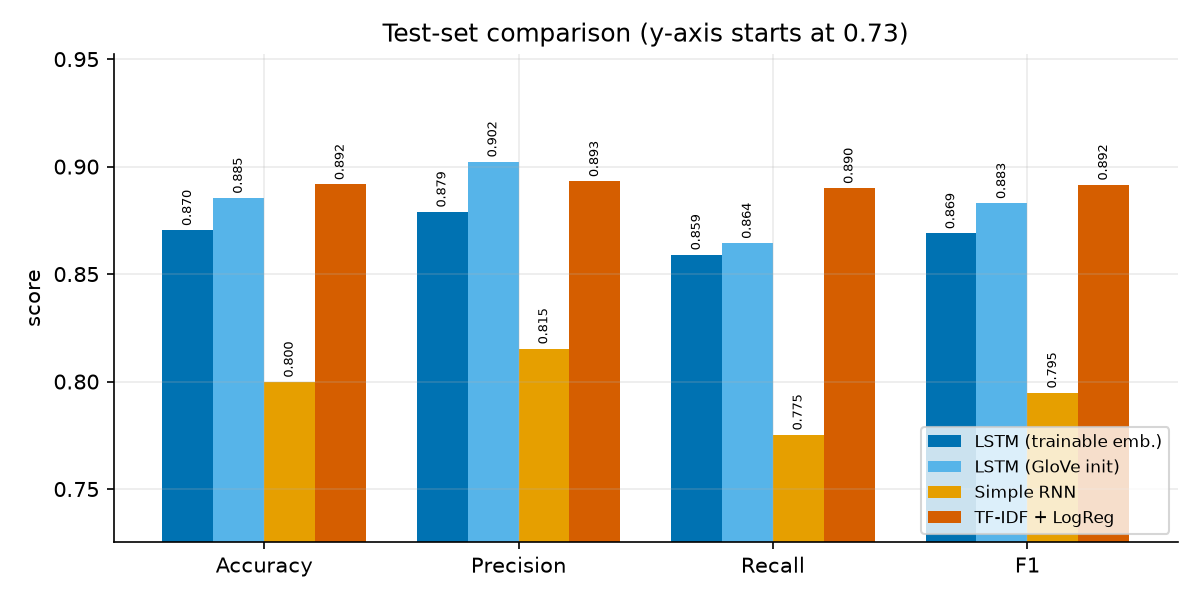

In [8]:
display(pd.read_csv(R/'metrics_overall.csv').round(4)); display(Image(F/'model_comparison.png'))

## Step 7 - Short vs long reviews

,model,group,n,accuracy,precision,recall,f1
0,lstm_emb,short,2986,0.8838,0.8962,0.8924,0.8943
1,lstm_emb,medium,3014,0.8723,0.8667,0.8649,0.8658
2,lstm_emb,long,3000,0.8553,0.8711,0.8147,0.8420
3,lstm_emb,all,9000,0.8704,0.8790,0.8591,0.8690
4,lstm_glove,short,2986,0.9025,0.9215,0.8997,0.9105
5,lstm_glove,medium,3014,0.8839,0.8879,0.8656,0.8766
6,lstm_glove,long,3000,0.8700,0.8943,0.8224,0.8568
7,lstm_glove,all,9000,0.8854,0.9023,0.8644,0.8830
8,rnn,short,2986,0.8242,0.8531,0.8225,0.8375
9,rnn,medium,3014,0.8013,0.8039,0.7709,0.7871


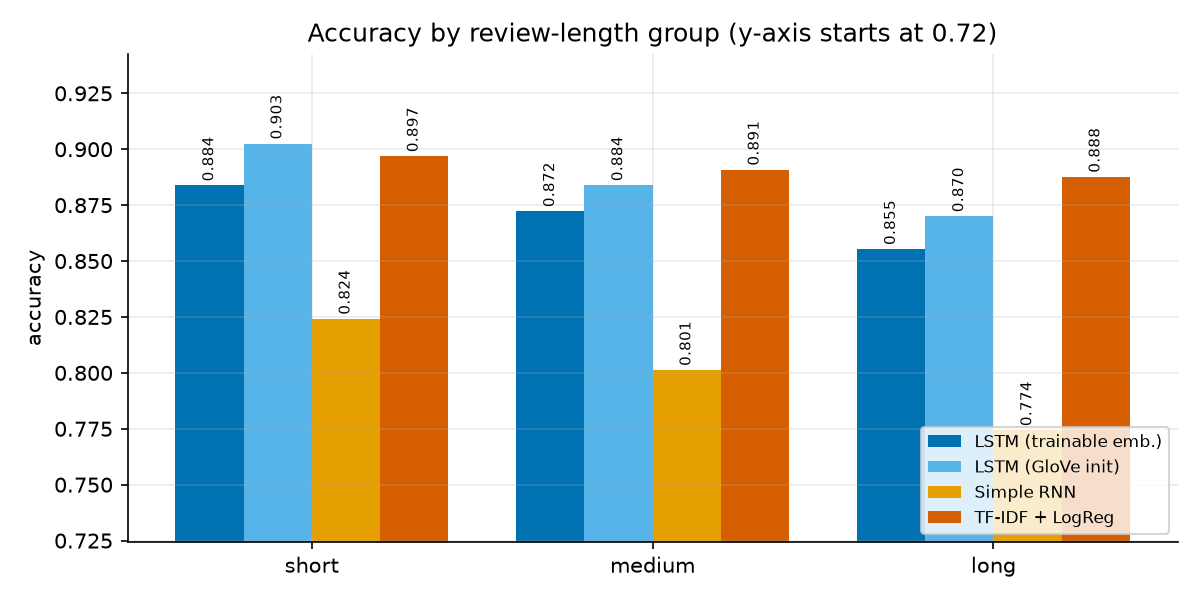

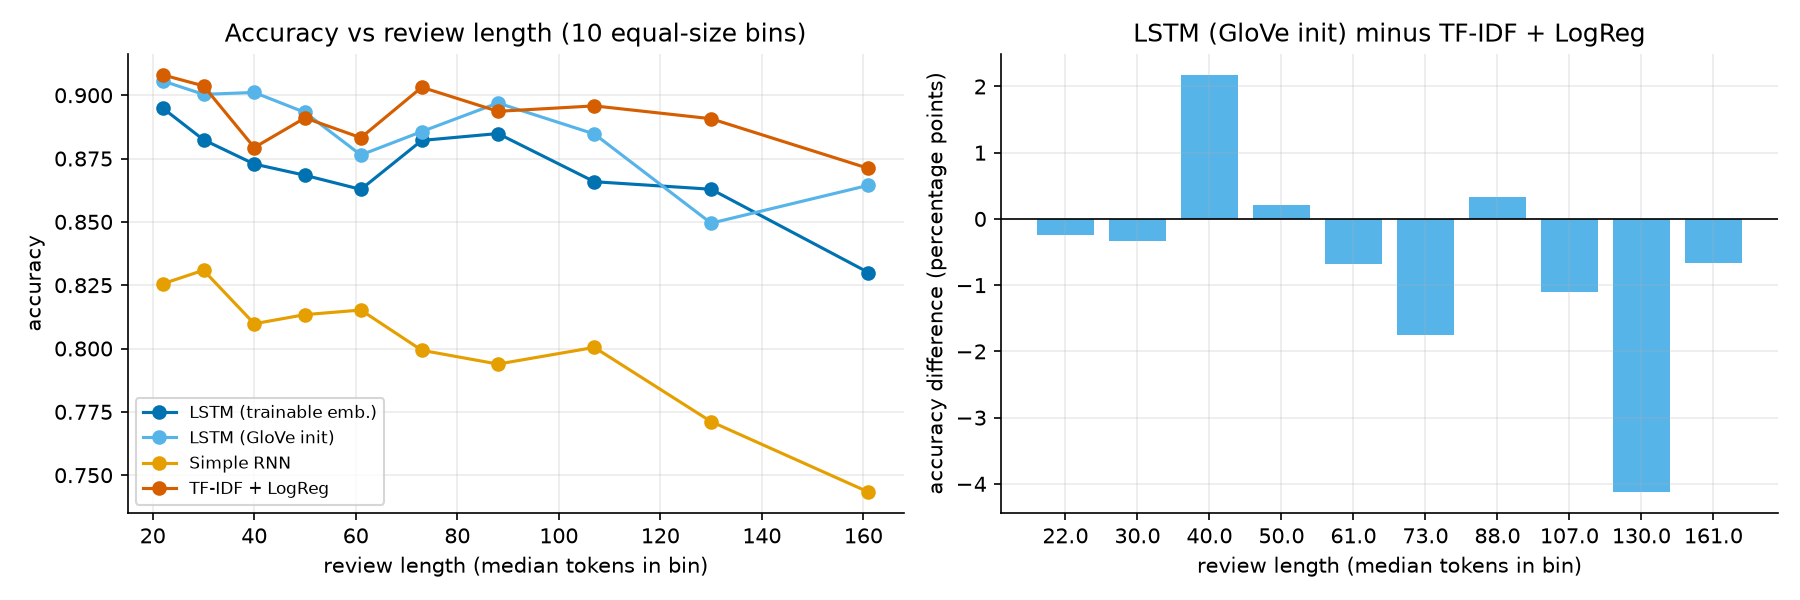

In [9]:
display(pd.read_csv(R/'metrics_by_length_group.csv').round(4)); display(Image(F/'accuracy_by_length_group.png')); display(Image(F/'accuracy_vs_length.png'))

In [10]:
for f in ['stats_accuracy_ci_by_group','stats_short_vs_long_gap','stats_main_vs_baseline_by_group','stats_advantage_change','error_cue_rates']:
    print(f); display(pd.read_csv(R/f'{f}.csv').round(4))

stats_accuracy_ci_by_group


,model,group,accuracy,ci_low,ci_high
0,lstm_emb,short,0.8838,0.8717,0.8959
1,lstm_emb,medium,0.8723,0.8603,0.8836
2,lstm_emb,long,0.8553,0.8430,0.8680
3,lstm_glove,short,0.9025,0.8922,0.9129
4,lstm_glove,medium,0.8839,0.8726,0.8955
5,lstm_glove,long,0.8700,0.8573,0.8817
6,rnn,short,0.8242,0.8104,0.8376
7,rnn,medium,0.8013,0.7870,0.8159
8,rnn,long,0.7743,0.7590,0.7893
9,tfidf_lr,short,0.8969,0.8858,0.9086


stats_short_vs_long_gap


,model,acc_short,acc_long,diff_short_minus_long,ci_low,ci_high,chi2_p_value
0,lstm_emb,0.8838,0.8553,0.0285,0.0118,0.0455,0.0012
1,lstm_glove,0.9025,0.8700,0.0325,0.0175,0.0486,0.0001
2,rnn,0.8242,0.7743,0.0498,0.0298,0.0695,0.0000
3,tfidf_lr,0.8969,0.8877,0.0092,-0.0062,0.0252,0.2695


stats_main_vs_baseline_by_group


,group,n,acc_main,acc_base,diff_main_minus_base,ci_low,ci_high,main_only_correct,base_only_correct,mcnemar_p_value
0,short,2986,0.9025,0.8969,0.0057,-0.0044,0.0157,134,117,0.3125
1,medium,3014,0.8839,0.8908,-0.0070,-0.0179,0.0036,137,158,0.2442
2,long,3000,0.8700,0.8877,-0.0177,-0.0297,-0.0053,149,202,0.0054
3,all,9000,0.8854,0.8918,-0.0063,-0.0128,0.0004,420,477,0.0615


stats_advantage_change


,main,base,advantage_short,advantage_long,change_long_minus_short,ci_low,ci_high
0,lstm_glove,tfidf_lr,0.0057,-0.0177,-0.0234,-0.0398,-0.0073


error_cue_rates


,group,wrong,n,has_negation,has_contrast,has_exclaim,truncated,n_tokens
0,long,False,2610,0.876,0.705,0.332,0.082,129.800
1,long,True,390,0.882,0.746,0.267,0.092,132.200
2,short,False,2695,0.472,0.269,0.203,0.000,32.339
3,short,True,291,0.512,0.344,0.127,0.000,32.491


In [11]:
display(Markdown((R/'error_examples.md').read_text(encoding='utf8')))

- **short** | 21 tokens | true=pos | P(pos)=0.11 | baseline predicted neg | truncated=False
  > this product has stopped my dizzy spells and decreased the ringing in my ears. you should use it for 2 months.

- **short** | 48 tokens | true=neg | P(pos)=0.97 | baseline predicted pos | truncated=False
  > I am a big Philosophy fan.I have bought the best facial cleanser ever from them(Purity).I have two other fragrances that I bought scent unsmelled, from them. Amazing Grace is lovely and Pure Grace is tremendous. Get them. Don't buy Falling in Love. It's yucky.

- **short** | 29 tokens | true=pos | P(pos)=0.43 | baseline predicted neg | truncated=False
  > If you have not watched this DVD or read the book, you are missing out! Believe and you shall receive! Your desires are controlled by you!

- **short** | 24 tokens | true=neg | P(pos)=0.90 | baseline predicted neg | truncated=False
  > REally thought this was a collection of comic books. It ended up being a cartoon DVD. I am keeping it because it was inexpensive.

- **short** | 36 tokens | true=neg | P(pos)=0.81 | baseline predicted pos | truncated=False
  > This is a very...book and the questions are so easy and simple. It might be ok if you are in the 500-650 range, but if you want more, go for Kaplan and Princeton Review.

- **short** | 42 tokens | true=neg | P(pos)=0.57 | baseline predicted pos | truncated=False
  > I thought this would be a comprehensive overview of LA area private schools. However, it does not cover the South Bay area (beach cities + Torrance + Palos Verdes), which is what I need. Probably great if you live between Santa Monica and Glendale.

- **short** | 39 tokens | true=pos | P(pos)=0.05 | baseline predicted neg | truncated=False
  > it is well built. i used it extensively without problem. its voltage is only 95V however. when i try to return it for this poor voltage, amazon does not allow me. it is somehow put into flammable category.

- **short** | 30 tokens | true=neg | P(pos)=0.77 | baseline predicted neg | truncated=False
  > In this "improved" set up, you have to hold the roller in your right hand, unlike the previous design, which was usable for both right handed and left handed people.

- **long** | 103 tokens | true=neg | P(pos)=0.57 | baseline predicted neg | truncated=False
  > S.P. Somtow writes wonderful short stories and I can easily recommend them. His novel "Jasmine Nights" is very well written, extremely entertaining and on my list for one of the best books I read last year.Unfortunately "Vanitas" was a bit tough for me to get through. I don't think the author spent much time editing this book and in the end, I was to the point of not caring what happened.I was looking forward to enjoying this book, but I didn't. Save your time and skip this one but DO read "Jasmine Nights" - you will not be sorry.

- **long** | 102 tokens | true=pos | P(pos)=0.25 | baseline predicted pos | truncated=False
  > never listened to Ryan Adams before this cd. never heard of Gold or the NY song (till getting Cold Roses then digging deeper)--been off the radio for a while now. simply came across his web site kinda on a fluke and 'let it ride' started to play. i don't know why, but it put its hooks in me then and hasn't let go. love the diversity of the album--don't care if all songs are in the same genre or not--just give me great songs! Cold Roses does. Over and over. Thanks Ryan. You too Cardinals.

- **long** | 156 tokens | true=neg | P(pos)=0.55 | baseline predicted neg | truncated=False
  > If you want an ice crusher - this is it. It can crush ice without any liquid at any speed. However, if you want a smooth texture, this will not do the job. I mainly use blenders for smoothies and to puree soup. Because of the blunt blade and wide bottom - it will not emulsify no matter how long you run it. When I made my smoothie, I ran it longer to see if it would become a creamy consistency (like I would get from my other blender) but it just made the ingredients warm. Another problem is that it doensn't handle single portions well. It splashes all over the jar making it impossible to add ingredients without getting it in your hair and making it necessary to scrape the sides. I returned it

- **long** | 109 tokens | true=neg | P(pos)=0.86 | baseline predicted neg | truncated=False
  > The book 'get tough' truly has balls to the walls techniques - direct and brutal. However, readers should note that this is not the complete hand to hand combat manual that this gentleman published. Some techniques and procedures are actually missing from this "compilation."Secondly, although the techniques are direct and brutal they are limited only to techniques that are executed (1) with combat uniforms (fatigues, boots etc.), (2) standing upright and (3) against one opponent always. In the today's world these techniques may have their shortfalls.The book is good for reference purpose (history maybe) and is not the be all and end all of hand to hand fighting.

- **long** | 136 tokens | true=pos | P(pos)=0.44 | baseline predicted pos | truncated=False
  > After meeting Jack Oran in 1994, I read the book of his experiences during the holocaust and after. I recommend it to anyone who is interested in reading a first-hand account of months in a prison camp, on the death march and piecing together a life after the war. There were days when I couldn't put it down and others when I could only read short passages. The message that this man brngs to us is that prejudice in any form is wrong and dangerous. This was the first book I had read about the holocaust. Each year I take a student group to the Holocaust Museum in Houston so that they might better understand the history they learn in textbooks. I am ordering two more copies to loan to my student

- **long** | 141 tokens | true=pos | P(pos)=0.34 | baseline predicted pos | truncated=False
  > Evokes the color and atmosphere of the fight game in post WWII San Francisco from a "roman noir" perspective. Tough dames, wise cracking reporter, hard luck fighter and a host of streetwise characters. Muller reproduces the jargon of the era with an expert ear. The language, description and characterizatons are worth the price of admission. The story gets off to a terrific start, then the pace falters until the action is revitalized at the end. As the mystery and doublecrosses are unraveled, plot credability weakens and the reader becomes aware of the author's strained attempt to clean up messy loose ends. The little stories spun within the novel enhance the characters and entertain the read

- **long** | 120 tokens | true=pos | P(pos)=0.42 | baseline predicted pos | truncated=False
  > I have owned already many digital cameras from so-so to high-end kinds; from Minolta Dimage S414 to latest Canon Xt. Ofcourse there are pros and cons for every single one of them. However, for the price I paid and the quality that I received - I am very very impressed by this Fuji V10. For those who loves to complain about the low light environment, go ahead to buy something else that you think it's better; I bet that you will regret to waste your hard earned money down the drain for getting the similar type of blurry, grainy, yellowish image results...I spent $450.00 for the Canon SD900 for my gf as Xmas gift

- **long** | 129 tokens | true=pos | P(pos)=0.36 | baseline predicted pos | truncated=False
  > This was the best film of 2001 I saw this in Branson last summer with my sister and mom and she had to buy the soundtrack right away but what next? how about a sequel? according to upcomingmovies.com and comingsoon.net the cast hasn't got a sequel signed yet but I hope they get it filmed this December for a August 2003 release in but the little plot that I've been rumored about is that Mia will be going to college. I really hope they don't replace Anne Hathaway with Christina Ricci no that won't happen, will it? anyways there is a possibility of a sequel but in the mean time enjoy the first one and have hopes for a sequel....

